<a href="https://colab.research.google.com/github/jnivasreddy/ML-Models/blob/main/ML_Classic_Cars24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Who Will Sell? Building your first ML pipeline

**Cars24** gets about **1 lakh** estimate requests every month, but has only a few evaluators to send out.

We have **5,000 past leads**, and for each one we know whether the customer sold their car within 30 days.

**Our job:** build a model that looks at a new lead and predicts: *will this person sell?*

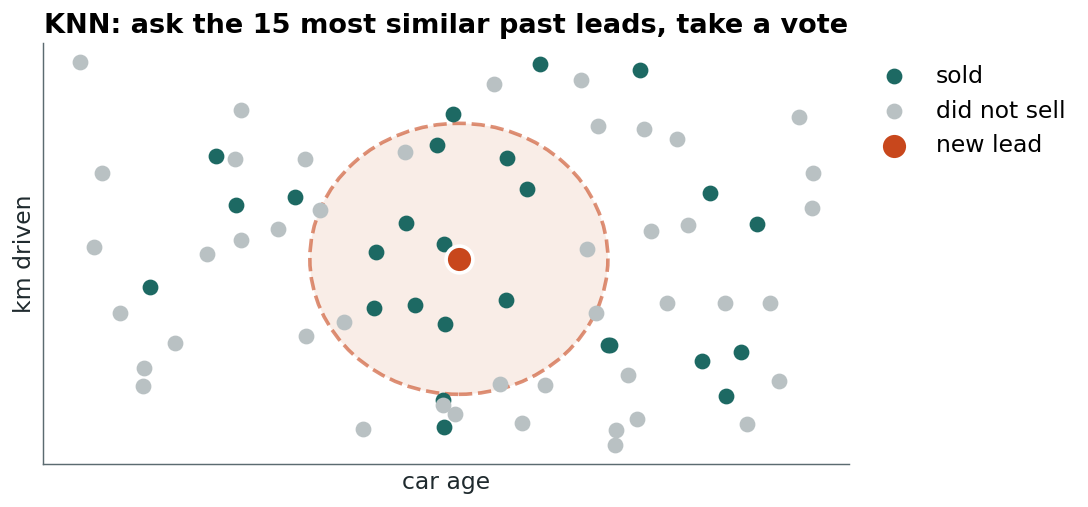

# Part 1: Getting the model to work

## 1. Meet the data

In [ ]:
import pandas as pd
df = pd.read_csv("cars24_leads.csv")
df.head()

,lead_id,brand,fuel,city,owner_number,car_age,km_driven,price_gap_pct,day_of_month,sold
0,11669,Maruti,Petrol,Mumbai,First,14,NaN,9.0,9,0
1,14069,Mahindra,CNG,Pune,First,9,90700.0,18.0,19,0
2,11164,Honda,Diesel,Bengaluru,First,7,60300.0,-7.0,23,1
3,10466,Tata,Petrol,Mumbai,First,14,189100.0,20.0,25,0
4,11000,Maruti,Diesel,Delhi,First,2,11700.0,4.0,16,1


In [ ]:
df.shape

(5000, 10)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   lead_id        5000 non-null   int64  
 1   brand          5000 non-null   object 
 2   fuel           5000 non-null   object 
 3   city           5000 non-null   object 
 4   owner_number   5000 non-null   object 
 5   car_age        5000 non-null   int64  
 6   km_driven      4400 non-null   float64
 7   price_gap_pct  5000 non-null   float64
 8   day_of_month   5000 non-null   int64  
 9   sold           5000 non-null   int64  
dtypes: float64(2), int64(4), object(4)
memory usage: 390.8+ KB


One row = one lead.

| Column | Meaning |
|---|---|
| `lead_id` | Serial number of the lead |
| `brand`, `fuel`, `city` | About the car and where it is |
| `owner_number` | First, second or third owner |
| `car_age` | Age of the car in years |
| `km_driven` | Kilometres on the odometer |
| `price_gap_pct` | How much more the customer expects than our estimate, in % |
| `day_of_month` | Day the lead came in |
| **`sold`** | **Our answer column: 1 = sold within 30 days, 0 = did not** |

## 2. Encoding text columns

Let's hand the data to our model and press Run.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
X = df.drop(columns="sold")
y = df["sold"]
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X, y)

ValueError: could not convert string to float: 'Maruti'

### 💡 The model only understands numbers

Can we just number the brands?

| Brand | Number |
|---|---|
| Maruti | 1 |
| Hyundai | 2 |
| Tata | 3 |

❌ Now the model thinks **Tata = 3 × Maruti**, and that Hyundai sits "between" them. That is nonsense.

✅ **One-hot encoding:** give every brand its own yes/no column.

| Brand | brand_Maruti | brand_Hyundai | brand_Tata |
|---|---|---|---|
| Maruti | 1 | 0 | 0 |
| Hyundai | 0 | 1 | 0 |
| Tata | 0 | 0 | 1 |

✅ **Ordered values** like First, Second, Third owner already have an order, so we simply number them **1, 2, 3**.

In [ ]:
df["owner_number"] = df["owner_number"].map({"First": 1, "Second": 2, "Third": 3})
df.head()

,lead_id,brand,fuel,city,owner_number,car_age,km_driven,price_gap_pct,day_of_month,sold
0,11669,Maruti,Petrol,Mumbai,1,14,NaN,9.0,9,0
1,14069,Mahindra,CNG,Pune,1,9,90700.0,18.0,19,0
2,11164,Honda,Diesel,Bengaluru,1,7,60300.0,-7.0,23,1
3,10466,Tata,Petrol,Mumbai,1,14,189100.0,20.0,25,0
4,11000,Maruti,Diesel,Delhi,1,2,11700.0,4.0,16,1


In [ ]:
df = pd.get_dummies(df, columns=["brand", "fuel", "city"])
df.head()

,lead_id,owner_number,car_age,km_driven,price_gap_pct,day_of_month,sold,brand_Honda,brand_Hyundai,brand_Mahindra,brand_Maruti,brand_Tata,fuel_CNG,fuel_Diesel,fuel_Petrol,city_Bengaluru,city_Delhi,city_Mumbai,city_Pune
0,11669,1,14,NaN,9.0,9,0,False,False,False,True,False,False,False,True,False,False,True,False
1,14069,1,9,90700.0,18.0,19,0,False,False,True,False,False,True,False,False,False,False,False,True
2,11164,1,7,60300.0,-7.0,23,1,True,False,False,False,False,False,True,False,True,False,False,False
3,10466,1,14,189100.0,20.0,25,0,False,False,False,False,True,False,False,True,False,False,True,False
4,11000,1,2,11700.0,4.0,16,1,False,False,False,True,False,False,True,False,False,True,False,False


## 3. Missing data

Everything is a number now. Run again.

In [ ]:
X = df.drop(columns="sold")
y = df["sold"]
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X, y)

ValueError: Input X contains NaN.
KNeighborsClassifier does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
df.isnull().sum()

,0
lead_id,0
owner_number,0
car_age,0
km_driven,600
price_gap_pct,0
day_of_month,0
sold,0
brand_Honda,0
brand_Hyundai,0
brand_Mahindra,0


### 💡 Fill the blanks with a typical value

Some customers skipped the km driven field. We fill each blank with the **median**: line up all the values and take the one in the middle.

| lead | km_driven | | lead | km_driven |
|---|---|---|---|---|
| A | 38,000 | | A | 38,000 |
| B | **blank** | ➜ | B | **median** |
| C | 1,10,000 | | C | 1,10,000 |

In [ ]:
km_median = df["km_driven"].median()
print(km_median)

88050.0


In [ ]:
df["km_driven"] = df["km_driven"].fillna(km_median)
df.isnull().sum()

,0
lead_id,0
owner_number,0
car_age,0
km_driven,0
price_gap_pct,0
day_of_month,0
sold,0
brand_Honda,0
brand_Hyundai,0
brand_Mahindra,0


In [ ]:
X = df.drop(columns="sold")
y = df["sold"]
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X, y)

KNeighborsClassifier(n_neighbors=15)

It trains! 🎉

### ✋ Quick check

**Why did the model crash on the brand column?**

- **A.** The brand column had too many blanks
- **B.** The model can only read numbers, not text
- **C.** Brand names must be sorted alphabetically
- **D.** The brand column had fewer rows than others

<details><summary>Show answer</summary>

**B.** A model works with numbers only. Text like "Maruti" has to be encoded first.

</details>

## 4. Outliers

Before we go further, let's look at the picture our model sees.

Text(0, 0.5, 'km driven')

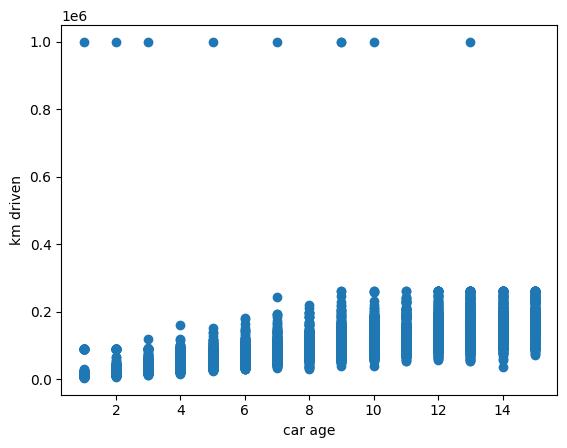

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(df["car_age"], df["km_driven"])
plt.xlabel("car age")
plt.ylabel("km driven")

### 💡 A few typing mistakes are squashing everyone

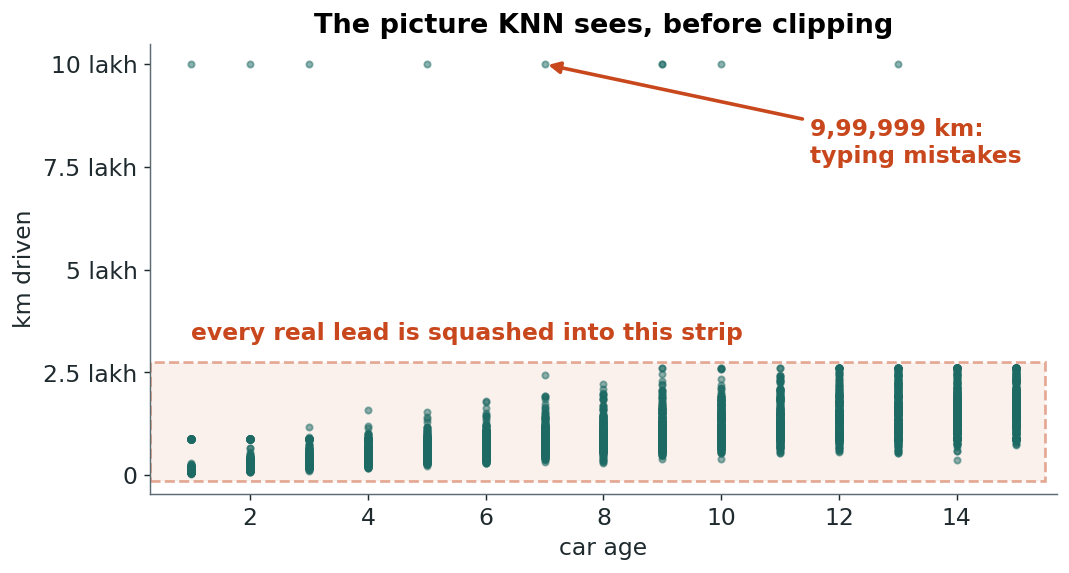

An **outlier** is a value far away from all the others. Here someone typed 9,99,999 km.

KNN finds similar leads on this very picture, so these few dots distort it for everyone.

✅ **Clip** km driven to a sensible limit: anything above 3,00,000 becomes 3,00,000.

Text(0, 0.5, 'km driven')

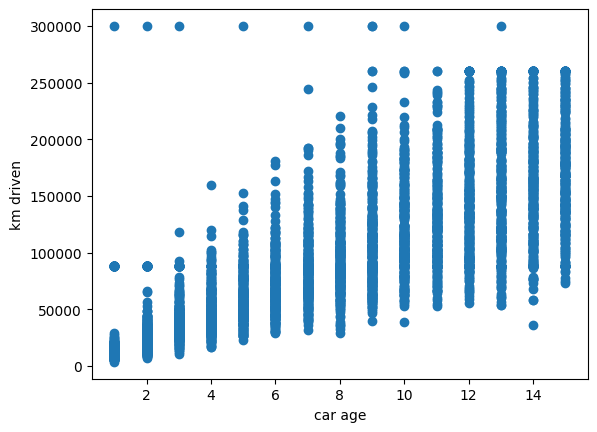

In [ ]:
df["km_driven"] = df["km_driven"].clip(upper=300000)
plt.scatter(df["car_age"], df["km_driven"])
plt.xlabel("car age")
plt.ylabel("km driven")

## 5. Binning

In [ ]:
df["km_driven"].head(10)

,km_driven
0,88050.0
1,90700.0
2,60300.0
3,189100.0
4,11700.0
5,18200.0
6,62800.0
7,211300.0
8,88050.0
9,25500.0


### 💡 Buyers think in ranges

Nobody thinks differently about **43,212 km** and **43,890 km**. People think "under 30k", "around 50k", "above 1 lakh".

**Binning** groups a number into bands:

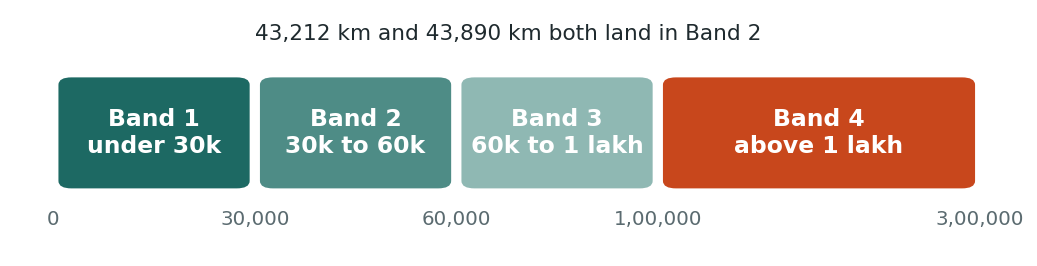

In [ ]:
df["km_band"] = pd.cut(df["km_driven"], bins=[0, 30000, 60000, 100000, 300000], labels=[1, 2, 3, 4]).astype(int)
df[["km_driven", "km_band"]].head(10)

,km_driven,km_band
0,88050.0,3
1,90700.0,3
2,60300.0,3
3,189100.0,4
4,11700.0,1
5,18200.0,1
6,62800.0,3
7,211300.0,4
8,88050.0,3
9,25500.0,1


<Axes: xlabel='km_band'>

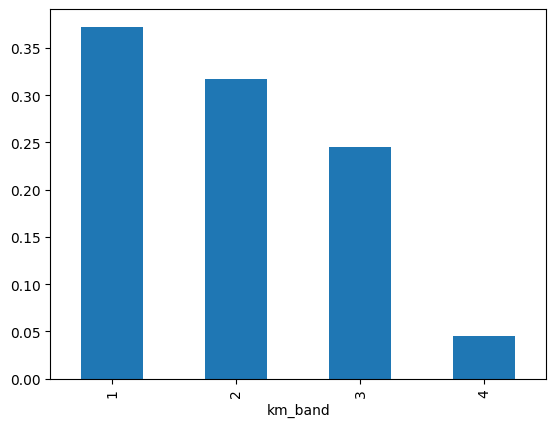

In [ ]:
df.groupby("km_band")["sold"].mean().plot(kind="bar")

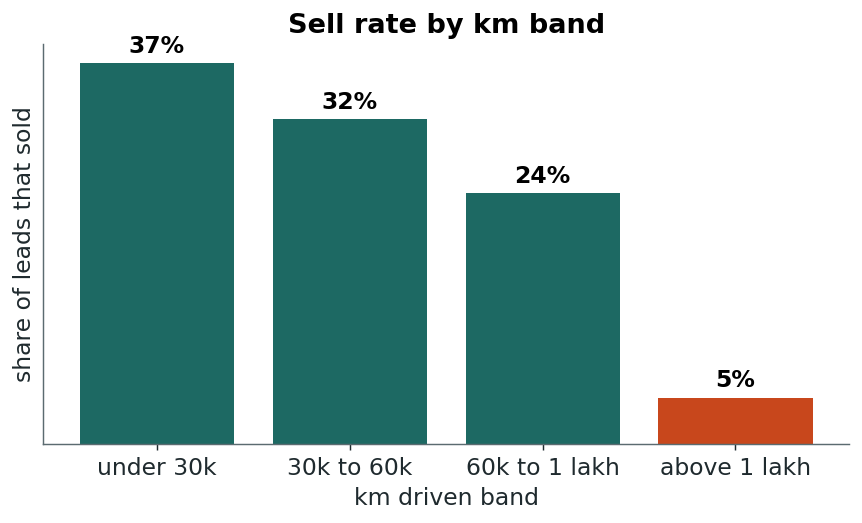

The bands make the pattern jump out: **above 1 lakh km, almost nobody sells.**

## 6. Train, validation and test split

The model trains. **But how do we know it works on leads it has never seen?**

### 💡 Practice, mock test, final exam

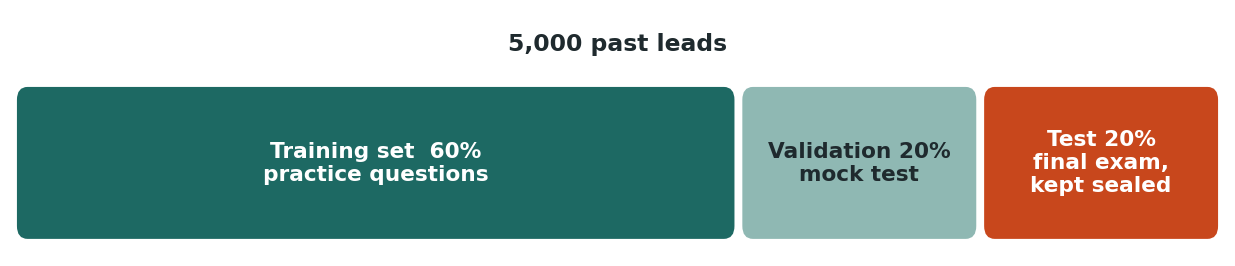

- **Training set:** the practice questions the model learns from
- **Validation set:** a mock test we check while improving the model
- **Test set:** the final exam, kept sealed until the very end

`stratify=y` keeps the same mix of sold and not-sold leads in every part.

In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop(columns="sold")
y = df["sold"]
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42)

In [ ]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(3000, 19)
(1000, 19)
(1000, 19)


In [ ]:
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X_train, y_train)
print(model.score(X_val, y_val))

0.796


Our first score: the share of mock test leads the model got right.

## 7. Scaling

In [ ]:
X_train[["km_driven", "car_age"]].head()

,km_driven,car_age
4787,257200.0,15
1232,223600.0,13
248,173100.0,10
1280,29600.0,1
3195,120300.0,12


### 💡 Big numbers shout

KNN measures how close two leads are. A gap of 40,000 km completely drowns out a gap of 8 years.

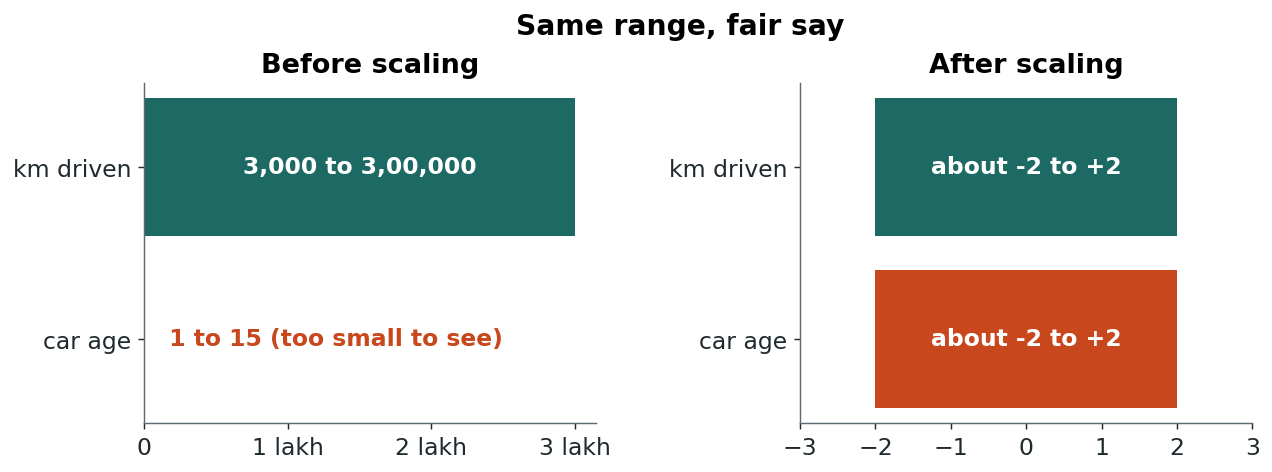

✅ **Scaling** puts every column on the same range, so each one gets a fair say.

- `fit_transform` on the training set: learn the scaling rule
- `transform` on the validation set: apply the same rule

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

In [ ]:
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X_train_scaled, y_train)
print(model.score(X_val_scaled, y_val))

0.834


The score goes up! 🎉

## 8. Feature selection

<Axes: xlabel='day_of_month'>

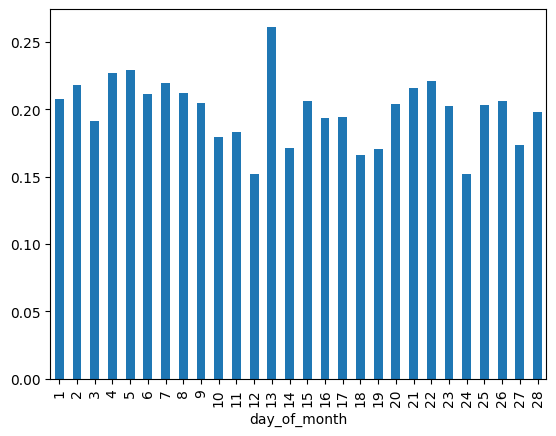

In [ ]:
df.groupby("day_of_month")["sold"].mean().plot(kind="bar")

### 💡 Keep only the columns that help

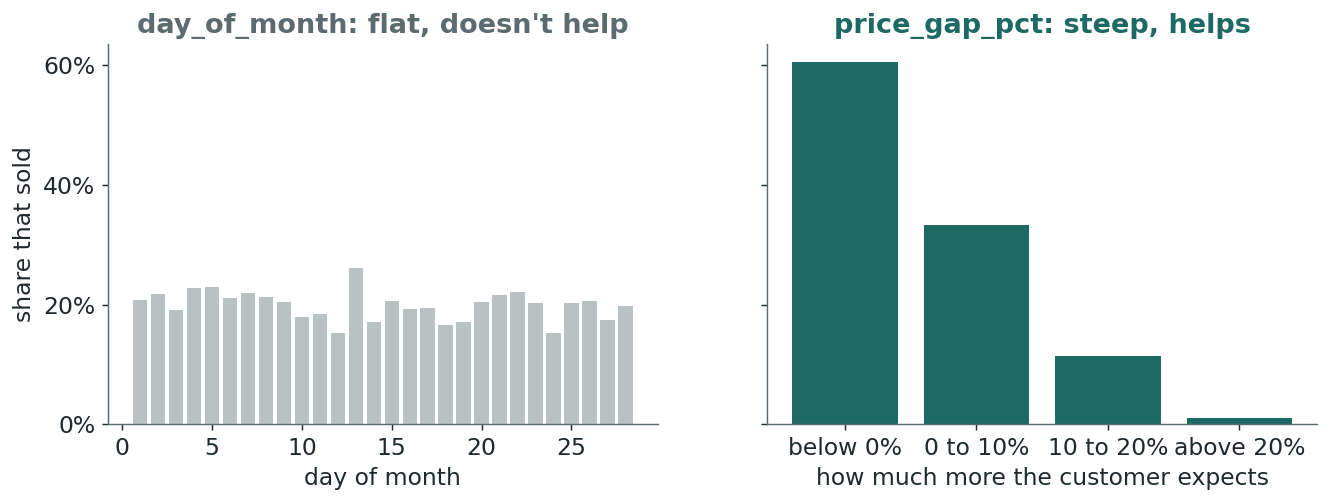

- `day_of_month` is flat: the day a lead came in tells us nothing
- `lead_id` is just a serial number

But KNN still counts both when it measures closeness, and they confuse it.

✅ **Feature selection:** keep only the columns that help.

In [ ]:
X_train_small = X_train.drop(columns=["lead_id", "day_of_month"])
X_val_small = X_val.drop(columns=["lead_id", "day_of_month"])

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_small)
X_val_scaled = scaler.transform(X_val_small)
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X_train_scaled, y_train)
print(model.score(X_val_scaled, y_val))

0.854


Up again! 🎉

### ✋ Quick check

**Why do we scale km driven and car age?**

- **A.** So large numbers do not drown out small ones
- **B.** So that the model trains faster on large data
- **C.** So that every column ends up with no blanks
- **D.** So that text columns turn into number columns

<details><summary>Show answer</summary>

**A.** KNN measures closeness. Scaling gives every column a fair say.

</details>

## 9. Pipeline

A brand new lead just came in from the website.

In [ ]:
new_lead = pd.DataFrame([{"lead_id": 50001, "brand": "Maruti", "fuel": "Petrol", "city": "Delhi",
                          "owner_number": "First", "car_age": 4, "km_driven": 38000,
                          "price_gap_pct": 5, "day_of_month": 12}])
new_lead

,lead_id,brand,fuel,city,owner_number,car_age,km_driven,price_gap_pct,day_of_month
0,50001,Maruti,Petrol,Delhi,First,4,38000,5,12


In [ ]:
model.predict(new_lead)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(


ValueError: could not convert string to float: 'Maruti'

### 💡 Every new lead needs the exact same steps

The new lead is raw. None of our steps have been applied to it.

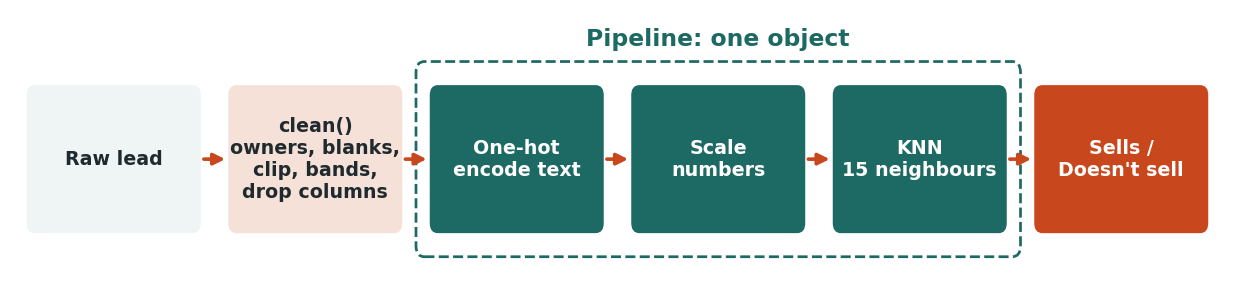

- **`clean()`**: one function with our fixed cleaning steps
- **Pipeline**: encoding, scaling and the model, packed into one object

Raw lead in, prediction out.

In [ ]:
def clean(data):
    data = data.copy()
    data["owner_number"] = data["owner_number"].map({"First": 1, "Second": 2, "Third": 3})
    data["km_driven"] = data["km_driven"].fillna(km_median)
    data["km_driven"] = data["km_driven"].clip(upper=300000)
    data["km_band"] = pd.cut(data["km_driven"], bins=[0, 30000, 60000, 100000, 300000], labels=[1, 2, 3, 4]).astype(int)
    data = data.drop(columns=["lead_id", "day_of_month"])
    return data

In [ ]:
raw = pd.read_csv("cars24_leads.csv")
clean_df = clean(raw)
clean_df.head()

,brand,fuel,city,owner_number,car_age,km_driven,price_gap_pct,sold,km_band
0,Maruti,Petrol,Mumbai,1,14,88050.0,9.0,0,3
1,Mahindra,CNG,Pune,1,9,90700.0,18.0,0,3
2,Honda,Diesel,Bengaluru,1,7,60300.0,-7.0,1,3
3,Tata,Petrol,Mumbai,1,14,189100.0,20.0,0,4
4,Maruti,Diesel,Delhi,1,2,11700.0,4.0,1,1


In [ ]:
X = clean_df.drop(columns="sold")
y = clean_df["sold"]
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

prep = ColumnTransformer([
    ("text", OneHotEncoder(handle_unknown="ignore"), ["brand", "fuel", "city"]),
    ("numbers", StandardScaler(), ["owner_number", "car_age", "km_driven", "price_gap_pct", "km_band"])
])
model = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=15))])
model.fit(X_train, y_train)
print(model.score(X_val, y_val))

0.88


In [ ]:
model

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('text',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['brand', 'fuel', 'city']),
                                                 ('numbers', StandardScaler(),
                                                  ['owner_number', 'car_age',
                                                   'km_driven', 'price_gap_pct',
                                                   'km_band'])])),
                ('knn', KNeighborsClassifier(n_neighbors=15))])

In [ ]:
print(model.predict(clean(new_lead)))
print(model.predict_proba(clean(new_lead)))

[1]
[[0.13333333 0.86666667]]


Raw lead in, prediction out. 🎉

### ✋ Quick check

**What is the main reason to put our steps into a pipeline?**

- **A.** It makes the model train on more past leads
- **B.** It removes the need for a final exam score
- **C.** It lets the model skip the scaling step
- **D.** Every new lead goes through the same steps

<details><summary>Show answer</summary>

**D.** A pipeline applies the exact same steps, in the same order, to every new lead.

</details>

# Part 2: Is the model any good?

## 10. The accuracy trap

Our model scores about 0.88. Before celebrating, let's look at the data itself: **how many leads actually sold?**

In [ ]:
df["sold"].value_counts()

,count
sold,
0,4008
1,992


<Axes: xlabel='sold'>

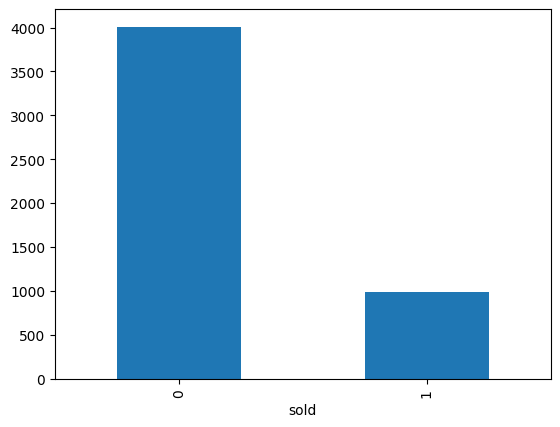

In [ ]:
df["sold"].value_counts().plot(kind="bar")

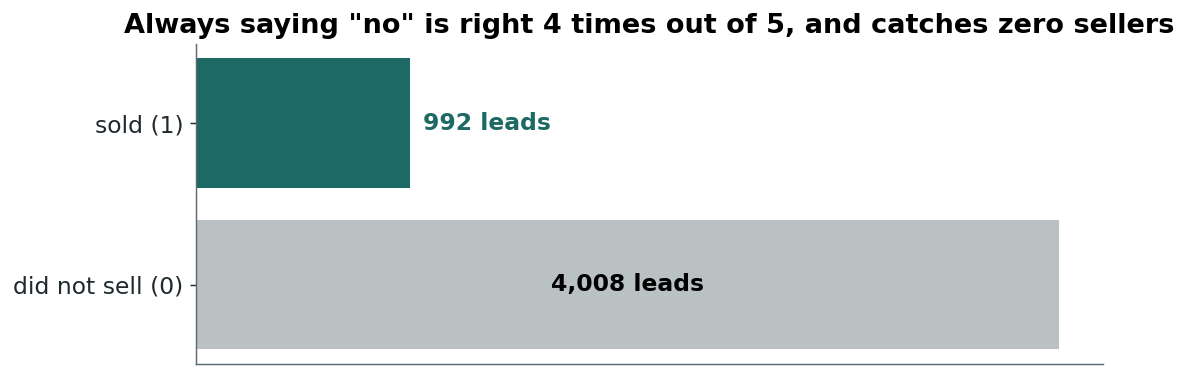

Only **1 in 5** leads sells. So what if a "model" ignores everything and always says **not sold**?

In [ ]:
from sklearn.dummy import DummyClassifier
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print(baseline.score(X_val, y_val))

0.801


### 💡 Accuracy can fool us

A lazy model that always says "not sold" is already about **80% accurate**, while catching **zero** sellers.

When one answer dominates, accuracy hides the mistakes. Let's look at the mistakes themselves.

## 11. Confusion matrix

Accuracy hid the mistakes. Let's count every kind of right and wrong answer on the 1,000 mock test leads.

In [ ]:
y_pred = model.predict(X_val)
y_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0])

`predict` gives 1 = sell (send an evaluator) or 0 = won't sell (skip).

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
print(confusion_matrix(y_val, y_pred))

[[783  18]
 [102  97]]


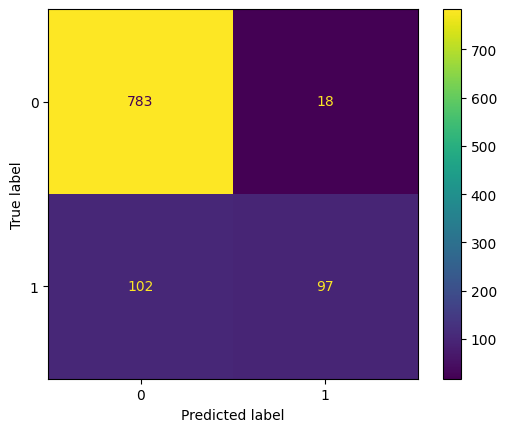

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_val, y_pred)

### 💡 Four boxes, four names

Every prediction lands in one box:

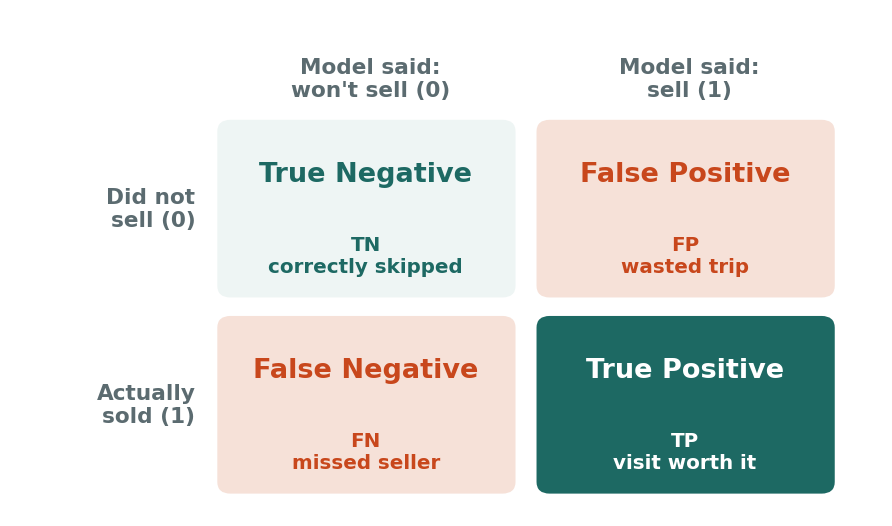

Read each name in two parts: **Positive / Negative** = what the model said. **True / False** = was it right?

Our model, in Cars24 words:

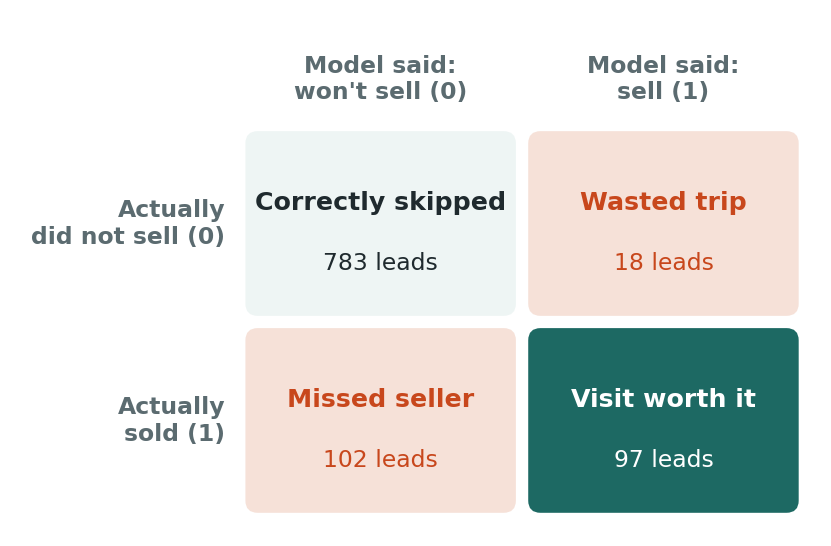

## 12. Precision: the Ops head's question

> "Stop wasting my evaluators' trips. **Of our visits, how many were worth it?**"

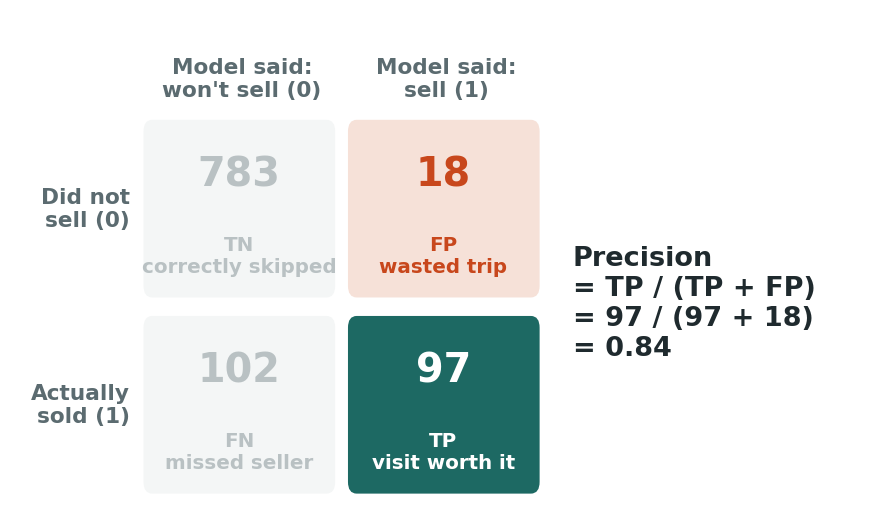

Precision looks only at the leads the model said **sell** to (the right column).

In [ ]:
from sklearn.metrics import precision_score
print(precision_score(y_val, y_pred))

0.8434782608695652


84 out of every 100 visits sell. Ops is happy.

## 13. Recall: the Growth head's question

> "Stop missing customers who wanted to sell. **Of all the sellers, how many did we reach?**"

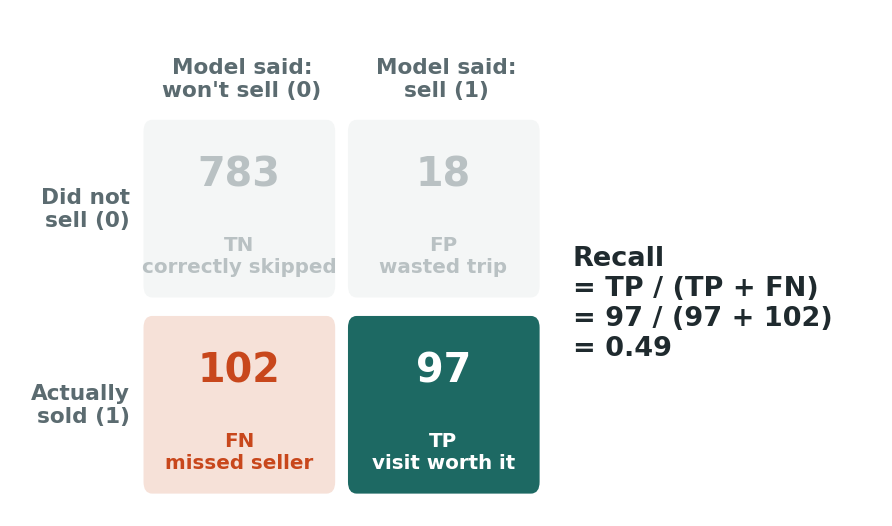

Recall looks only at the leads who **really sold** (the bottom row).

In [ ]:
from sklearn.metrics import recall_score
print(recall_score(y_val, y_pred))

0.48743718592964824


We reach only about **half** of the real sellers. Growth is not happy.

### ✋ Quick check

**Ops says too many evaluator trips are wasted. Which number do they want higher?**

- **A.** Precision, the share of visits that sold
- **B.** Recall, the share of real sellers we reached
- **C.** Accuracy, the share of all answers we got right
- **D.** The total count of leads in our data

<details><summary>Show answer</summary>

**A.** Wasted trips are false positives. Fewer of them means higher precision.

</details>

## 14. The model gives a chance. We choose the bar.

Behind every yes or no, the model has a **chance of selling** for each lead.

In [ ]:
y_prob = model.predict_proba(X_val)[:, 1]
y_prob[:10]

array([0.06666667, 0.        , 0.33333333, 0.26666667, 0.        ,
       0.        , 0.        , 0.66666667, 0.06666667, 0.        ])

### 💡 A bar turns the chance into a decision

Column 1 of `predict_proba` is the chance of selling. The default rule: **50% or more, send an evaluator. Below 50%, skip.**

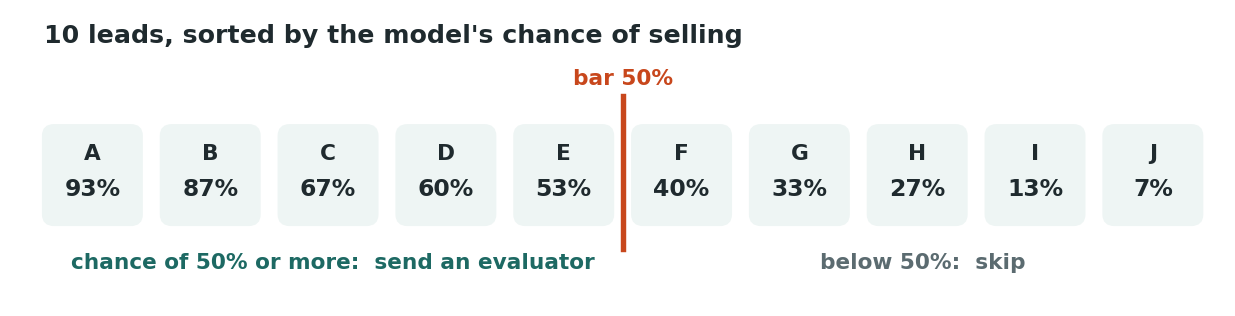

A month later, we know who really sold:

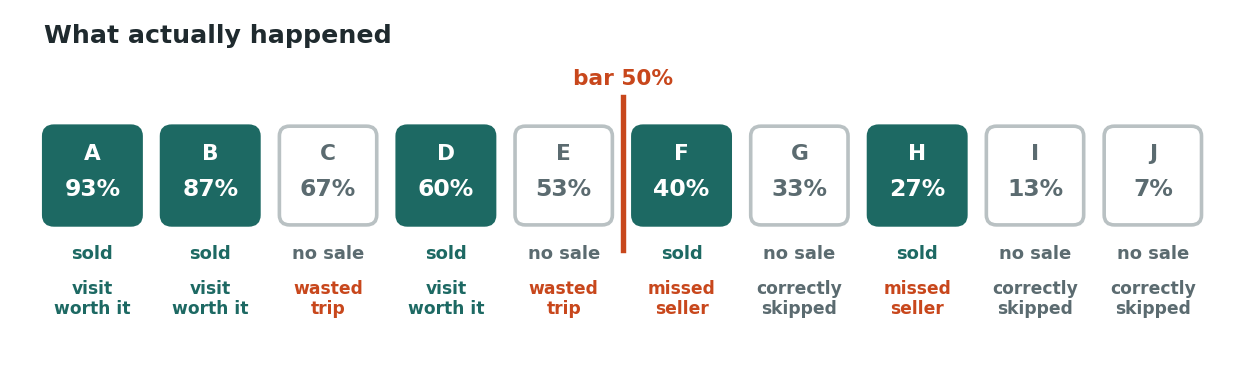

## 15. Moving the bar

The 50% bar is not fixed. **We can move it, without retraining anything.**

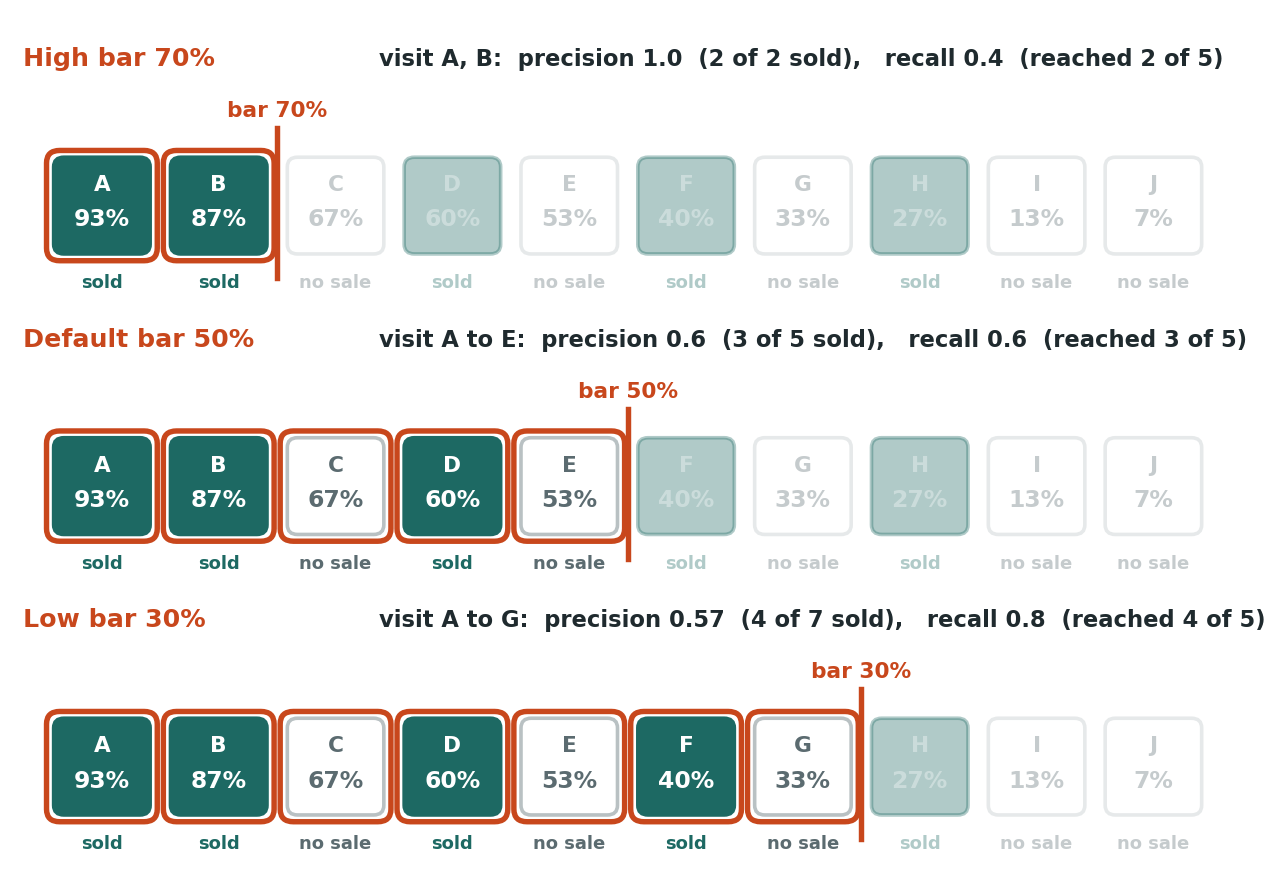

- **Raise the bar:** we visit fewer leads. Fewer wasted trips (**precision up**), but more missed sellers (**recall down**). Ops is happy.
- **Lower the bar:** we visit more leads. More sellers caught (**recall up**), but more wasted trips (**precision down**). Growth is happy.

Let's try it on all 1,000 mock test leads.

In [ ]:
y_pred_high = (y_prob >= 0.7).astype(int)
print(precision_score(y_val, y_pred_high))
print(recall_score(y_val, y_pred_high))

0.94
0.23618090452261306


In [ ]:
y_pred_mid = (y_prob >= 0.5).astype(int)
print(precision_score(y_val, y_pred_mid))
print(recall_score(y_val, y_pred_mid))

0.8434782608695652
0.48743718592964824


In [ ]:
y_pred_low = (y_prob >= 0.3).astype(int)
print(precision_score(y_val, y_pred_low))
print(recall_score(y_val, y_pred_low))

0.6086956521739131
0.7738693467336684


Same pattern as our 10 leads: **higher bar, precision up. Lower bar, recall up.**

| Bar | Precision | Recall | Who is happy? |
|---|---|---|---|
| 0.7 | 0.94 | 0.24 | Ops |
| 0.5 | 0.84 | 0.49 | |
| 0.3 | 0.61 | 0.77 | Growth |

### ✋ Quick check

**We raise the bar from 50% to 70%. What happens?**

- **A.** More sellers caught, and more wasted trips too
- **B.** Nothing changes, because the model is the same
- **C.** Fewer wasted trips, but fewer sellers caught
- **D.** More sellers caught, with no wasted trips

<details><summary>Show answer</summary>

**C.** A higher bar means we visit fewer leads: fewer wasted trips, but more missed sellers.

</details>

## 16. F1: one number for Ops and Growth together

Precision makes Ops happy, recall makes Growth happy. **Can one number tell us if both are reasonably happy?**

### 💡 F1 is high only when both are high

| Bar | Precision | Recall | F1 |
|---|---|---|---|
| 0.7 | 0.94 | 0.24 | **0.38** |
| 0.5 | 0.84 | 0.49 | **0.62** |
| 0.3 | 0.61 | 0.77 | **0.68** |

One very high number cannot hide one very low number. **From here on, F1 is our score.**

In [ ]:
from sklearn.metrics import f1_score
print(f1_score(y_val, y_pred_high))
print(f1_score(y_val, y_pred_mid))
print(f1_score(y_val, y_pred_low))

0.37751004016064255
0.6178343949044586
0.6814159292035398


### Why not just take the average?

Try a lazy model that says **sell** to every lead, so it visits everyone:

In [ ]:
y_pred_all = [1] * len(y_val)
print(precision_score(y_val, y_pred_all))
print(recall_score(y_val, y_pred_all))

0.199
1.0


Precision 0.20, recall 1.00. The **average is 0.60**, almost as good as our model's 0.67, yet this model wastes 4 trips out of every 5.

F1 does not fall for it:

In [ ]:
print(f1_score(y_val, y_pred_all))

0.33194328607172646


| Model | Precision | Recall | Average | F1 |
|---|---|---|---|---|
| Lazy: visit everyone | 0.20 | 1.00 | 0.60 | **0.33** |
| Our model | 0.84 | 0.49 | 0.67 | **0.62** |

If either number is low, F1 drops.

## 17. AUC: are the sellers at the top?

The call team rings leads **from the top of the list down**. So the order matters: a good model puts the real sellers near the top.

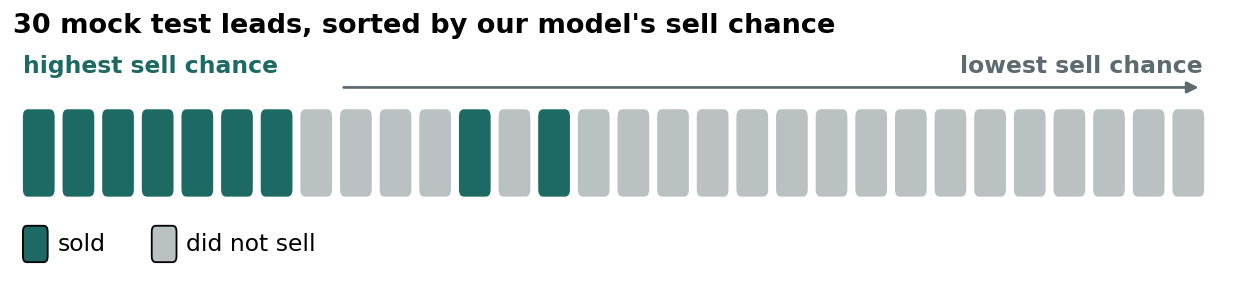

**AUC is a simple game:** pick one real seller and one non-seller at random. Did the model give the seller the higher chance? AUC = how often the model wins, over every possible pair.

**0.5** = coin toss, **1.0** = wins every pair.

In [ ]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
print(roc_auc_score(y_val, y_prob))

0.9264581333634465


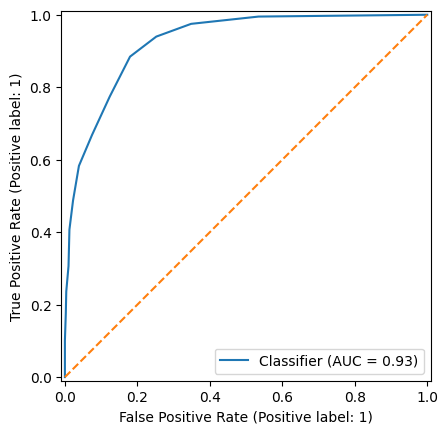

In [ ]:
RocCurveDisplay.from_predictions(y_val, y_prob)
plt.plot([0, 1], [0, 1], linestyle="--")

### 💡 Reading the curve: every point is one position of the bar

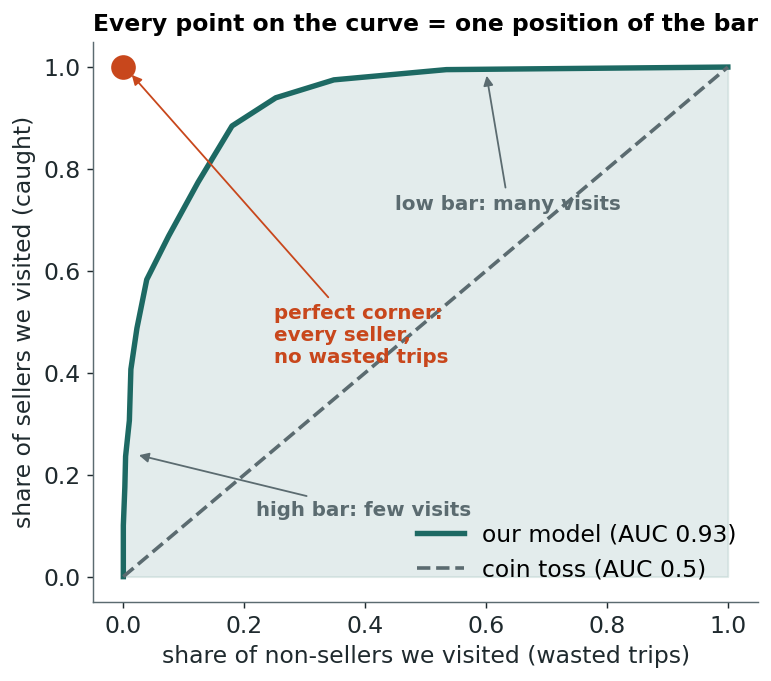

Slide the bar from high to low and we move along the curve. The closer the curve hugs the **top-left corner**, the more sellers we catch without wasted trips.

## 18. How many neighbours?

What if we ask just **1** neighbour?

In [ ]:
model_1 = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=1))])
model_1.fit(X_train, y_train)
print(f1_score(y_train, model_1.predict(X_train)))
print(f1_score(y_val, model_1.predict(X_val)))

1.0
0.5851063829787234


Perfect in practice, much worse in the mock test. And with **500** neighbours?

In [ ]:
model_500 = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=500))])
model_500.fit(X_train, y_train)
print(f1_score(y_train, model_500.predict(X_train)))
print(f1_score(y_val, model_500.predict(X_val)))

0.3973509933774834
0.3534136546184739


### 💡 Too few, too many, just right

- **1 neighbour:** the model memorises the practice leads. Perfect in practice, poor in the mock test. This is **overfitting** (high variance).
- **500 neighbours:** the model only sees the crowd, and the crowd mostly didn't sell. Poor everywhere. This is **underfitting** (high bias).
- **The sweet spot is in the middle.**

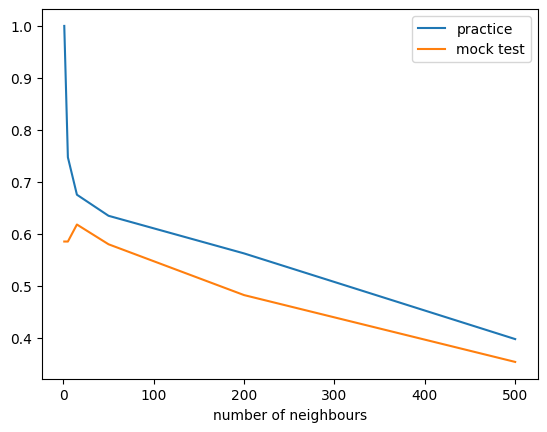

In [ ]:
ks = [1, 5, 15, 50, 200, 500]
practice = []
mock = []
for k in ks:
    m = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=k))])
    m.fit(X_train, y_train)
    practice.append(f1_score(y_train, m.predict(X_train)))
    mock.append(f1_score(y_val, m.predict(X_val)))
plt.plot(ks, practice, label="practice")
plt.plot(ks, mock, label="mock test")
plt.xlabel("number of neighbours")
plt.legend()

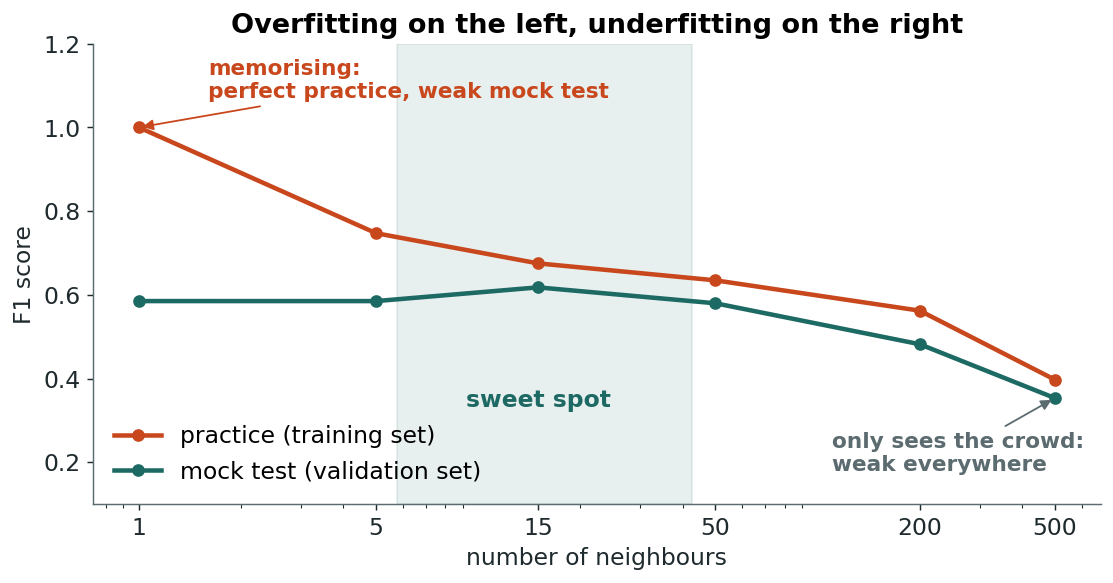

## 19. Cross-validation

Let's make two different mock tests out of the training data and score our model on each.

In [ ]:
X_a, X_b, y_a, y_b = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=1)
model.fit(X_a, y_a)
print(f1_score(y_b, model.predict(X_b)))

0.5583333333333333


In [ ]:
X_a, X_b, y_a, y_b = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=2)
model.fit(X_a, y_a)
print(f1_score(y_b, model.predict(X_b)))

0.625


Same model, two different scores. **Which one is true?**

### 💡 Take 5 mock tests and average them

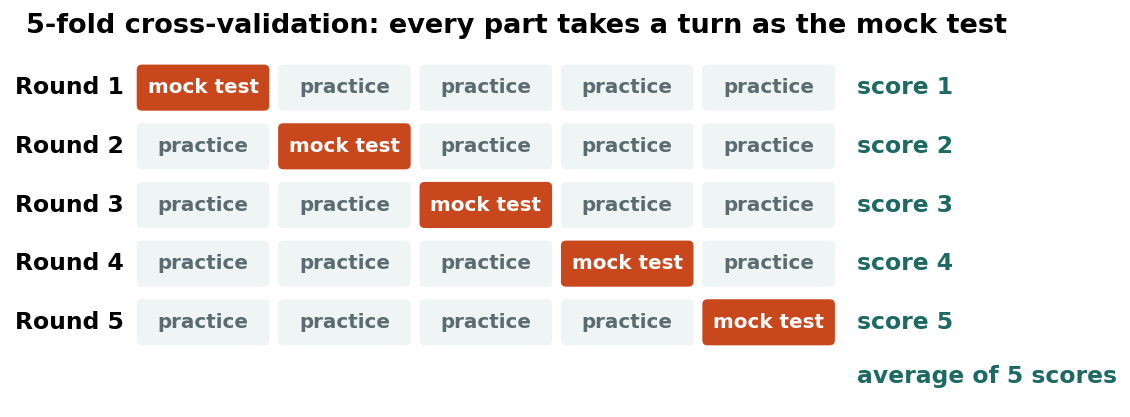

**Cross-validation** splits the training data into 5 parts. Each part takes one turn as the mock test, while the other 4 are used for practice. We average the 5 scores.

In [ ]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model, X_train, y_train, cv=5, scoring="f1")
print(scores)
print(scores.mean())

[0.58333333 0.65326633 0.58201058 0.64356436 0.63636364]
0.6197076479602973


## 20. Tuning

We picked 15 neighbours by hand. Is that the best? Let's try a few others by hand.

In [ ]:
model_5 = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=5))])
print(cross_val_score(model_5, X_train, y_train, cv=5, scoring="f1").mean())

0.6291952433929155


In [ ]:
model_60 = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=60))])
print(cross_val_score(model_60, X_train, y_train, cv=5, scoring="f1").mean())

0.6011190053961075


Slow, and pure guesswork.

### 💡 Let the computer turn the knobs

**Hyperparameters** are knobs *we* set before training. We have two:

- `n_neighbors`: how many neighbours to ask
- `weights`: do closer neighbours get a bigger vote? (`"uniform"` = no, `"distance"` = yes)

Three ways to search:

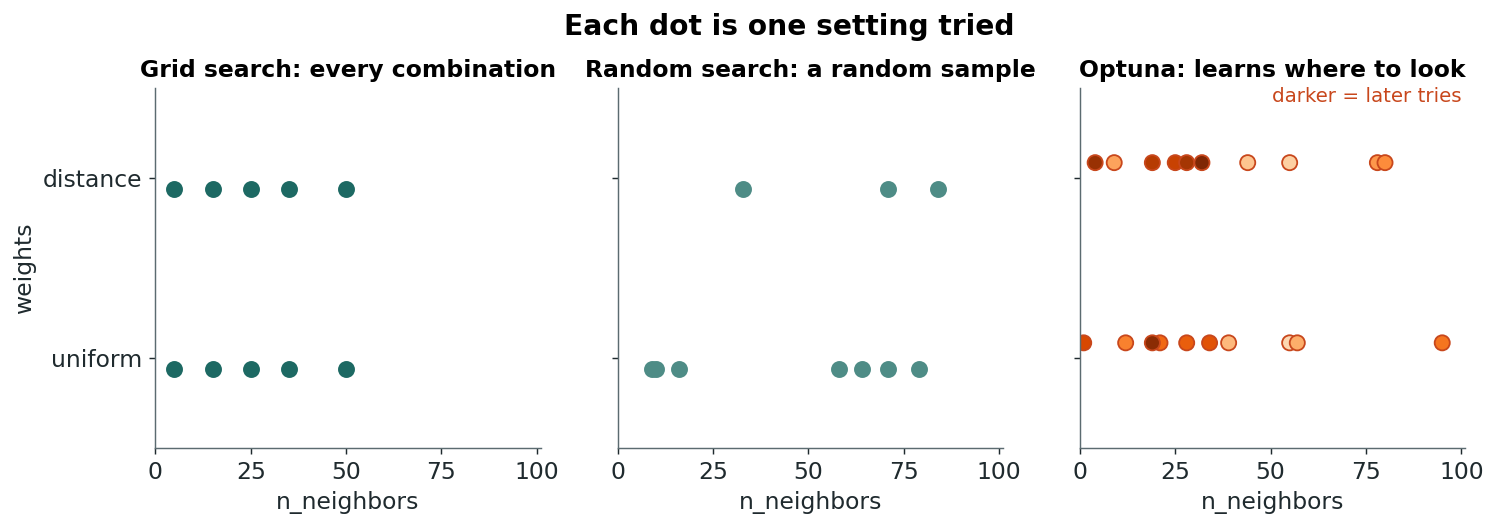

- **Grid search:** tries every combination
- **Random search:** tries a random sample of combinations
- **Optuna:** learns from each try and focuses on the promising area

`knn__n_neighbors` means: the `n_neighbors` knob inside the step we named `knn`.

In [ ]:
from sklearn.model_selection import GridSearchCV
knobs = {"knn__n_neighbors": [5, 15, 25, 35, 50], "knn__weights": ["uniform", "distance"]}
grid = GridSearchCV(model, knobs, cv=5, scoring="f1")
grid.fit(X_train, y_train)
print(grid.best_params_)
print(grid.best_score_)

{'knn__n_neighbors': 25, 'knn__weights': 'distance'}
0.6475240217070786


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
knobs = {"knn__n_neighbors": range(1, 100), "knn__weights": ["uniform", "distance"]}
rand = RandomizedSearchCV(model, knobs, n_iter=10, cv=5, scoring="f1", random_state=42)
rand.fit(X_train, y_train)
print(rand.best_params_)
print(rand.best_score_)

{'knn__weights': 'distance', 'knn__n_neighbors': 33}
0.6425473608924551


In [ ]:
!pip install optuna -q

In [ ]:
import optuna

def objective(trial):
    k = trial.suggest_int("n_neighbors", 1, 100)
    w = trial.suggest_categorical("weights", ["uniform", "distance"])
    m = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=k, weights=w))])
    return cross_val_score(m, X_train, y_train, cv=5, scoring="f1").mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=20)
print(study.best_params)
print(study.best_value)

[I 2026-10-24 07:19:29,474] A new study created in memory with name: no-name-a7eb83dc-3697-42ef-9f45-7155269434e8
[I 2026-10-24 07:19:29,913] Trial 0 finished with value: 0.6018066546525105 and parameters: {'n_neighbors': 57, 'weights': 'uniform'}. Best is trial 0 with value: 0.6018066546525105.
[I 2026-10-24 07:19:30,389] Trial 1 finished with value: 0.6175681305388321 and parameters: {'n_neighbors': 52, 'weights': 'distance'}. Best is trial 1 with value: 0.6175681305388321.
[I 2026-10-24 07:19:30,871] Trial 2 finished with value: 0.620141190108707 and parameters: {'n_neighbors': 44, 'weights': 'uniform'}. Best is trial 2 with value: 0.620141190108707.
[I 2026-10-24 07:19:31,427] Trial 3 finished with value: 0.6135881224154838 and parameters: {'n_neighbors': 66, 'weights': 'distance'}. Best is trial 2 with value: 0.620141190108707.
[I 2026-10-24 07:19:32,091] Trial 4 finished with value: 0.5999620303040872 and parameters: {'n_neighbors': 100, 'weights': 'distance'}. Best is trial 2 wi

{'n_neighbors': 19, 'weights': 'distance'}
0.6447179487179487


In [ ]:
optuna.visualization.plot_optimization_history(study)

Each dot is one try. The line shows the best score found so far: Optuna keeps climbing.

### ✋ Quick check

**With n_neighbors=1, the practice score is near perfect but the mock test score is low. What happened?**

- **A.** It found the best number of neighbours here
- **B.** It memorised the practice leads by heart
- **C.** It did not see enough practice leads
- **D.** It needs more columns to work well

<details><summary>Show answer</summary>

**B.** That is overfitting: the model copies the practice leads instead of learning the pattern.

</details>

## 21. The final exam

Time to open the sealed paper. We use the **test set once**, at the very end.

In [ ]:
best = grid.best_estimator_
y_pred_test = best.predict(X_test)
print(f1_score(y_test, y_pred_test))
print(confusion_matrix(y_test, y_pred_test))

0.5828220858895705
[[769  33]
 [103  95]]


Now save the model, so the Cars24 website can use it.

In [ ]:
import joblib
joblib.dump(best, "cars24_lead_model.pkl")

['cars24_lead_model.pkl']

In [ ]:
loaded = joblib.load("cars24_lead_model.pkl")
print(loaded.predict(clean(new_lead)))

[1]


## 🎉 Raw data in. A saved, tested model out.

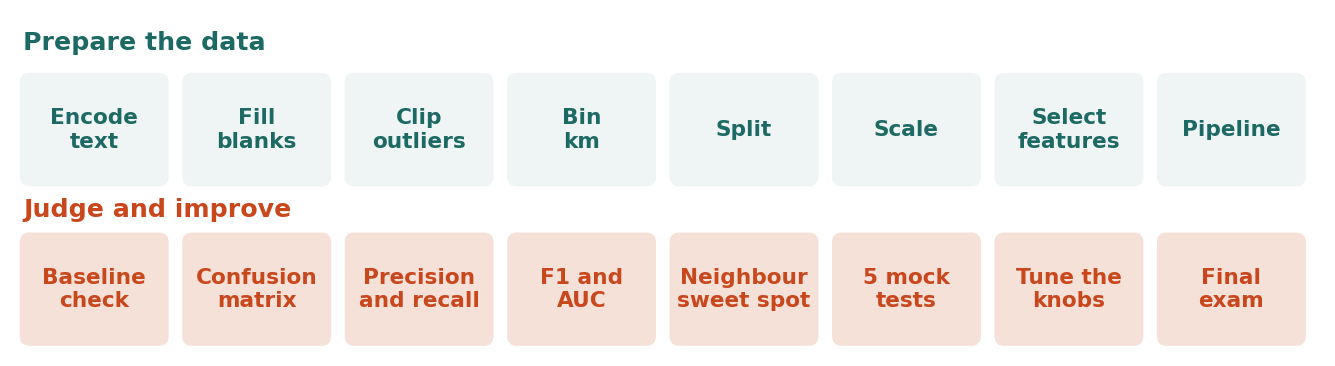